## Punto 1
Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. (10%)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Frecuencias de las tres componentes (Hz)
f1 = 40
f2 = 80
f3 = 160

# Amplitudes de cada componente (V), diferentes para poder distinguirlas despues
A1 = 5
A2 = 3
A3 = 2

# Frecuencia de muestreo minima (Nyquist): el doble de la frecuencia mas alta
fmax = max(f1, f2, f3)
Fs_min = 2 * fmax
print('Frecuencia maxima de la señal:', fmax, 'Hz')
print('Frecuencia de muestreo minima (Nyquist):', Fs_min, 'Hz')

# Frecuencia de muestreo que vamos a usar (igual a la de la guia)
Fs = 1000          # Hz
T = 1/Fs           # periodo de muestreo (s)
print('Frecuencia de muestreo usada:', Fs, 'Hz')
print('Muestras por ciclo de la componente de 160 Hz:', Fs/f3)

# Periodo de la señal completa: lo da la frecuencia mas baja (40 Hz),
# porque 80 y 160 son multiplos de 40
Tp = 1/f1
print('Periodo de la señal compuesta:', Tp, 's')

# Vector de tiempo con 10 periodos de la señal (250 muestras)
t = np.arange(0, 10*Tp, T)
print('Numero de muestras:', len(t))

# Señal: suma de las tres senoidales
x = A1*np.sin(2*np.pi*f1*t) + A2*np.sin(2*np.pi*f2*t) + A3*np.sin(2*np.pi*f3*t)

Frecuencia maxima de la señal: 160 Hz
Frecuencia de muestreo minima (Nyquist): 320 Hz
Frecuencia de muestreo usada: 1000 Hz
Muestras por ciclo de la componente de 160 Hz: 6.25
Periodo de la señal compuesta: 0.025 s
Numero de muestras: 250


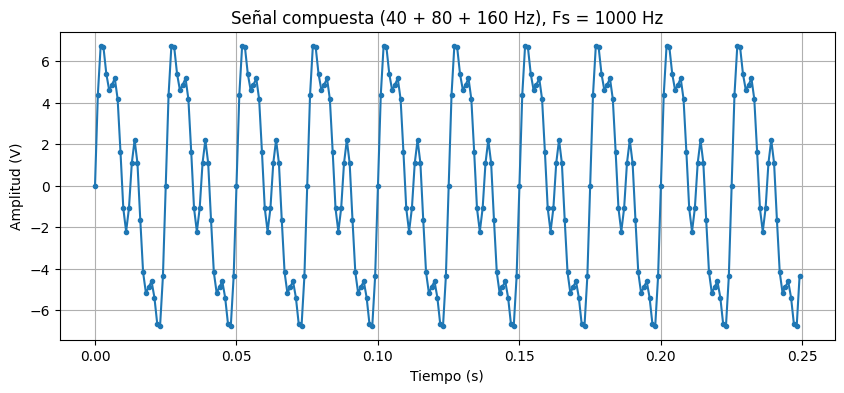

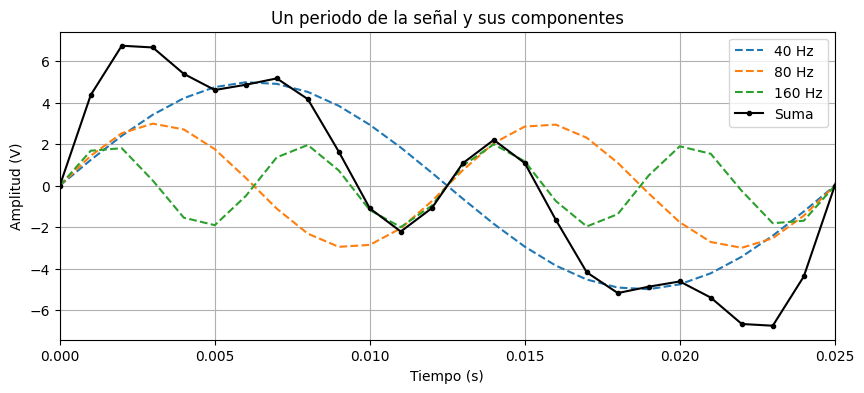

In [3]:
# Grafica de la señal completa (10 periodos)
plt.figure(figsize=(10, 4))
plt.plot(t, x, marker='o', markersize=3)
plt.title('Señal compuesta (40 + 80 + 160 Hz), Fs = 1000 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.grid()
plt.show()

# Zoom a un solo periodo, con cada componente por separado
plt.figure(figsize=(10, 4))
plt.plot(t, A1*np.sin(2*np.pi*f1*t), '--', label='40 Hz')
plt.plot(t, A2*np.sin(2*np.pi*f2*t), '--', label='80 Hz')
plt.plot(t, A3*np.sin(2*np.pi*f3*t), '--', label='160 Hz')
plt.plot(t, x, 'k', marker='o', markersize=3, label='Suma')
plt.xlim(0, Tp)   # solo un periodo (0.025 s)
plt.title('Un periodo de la señal y sus componentes')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend()
plt.grid()
plt.show()

Primeras muestras de la componente de 160 Hz a 320 Hz: [ 0.  0. -0. -0. -0.]


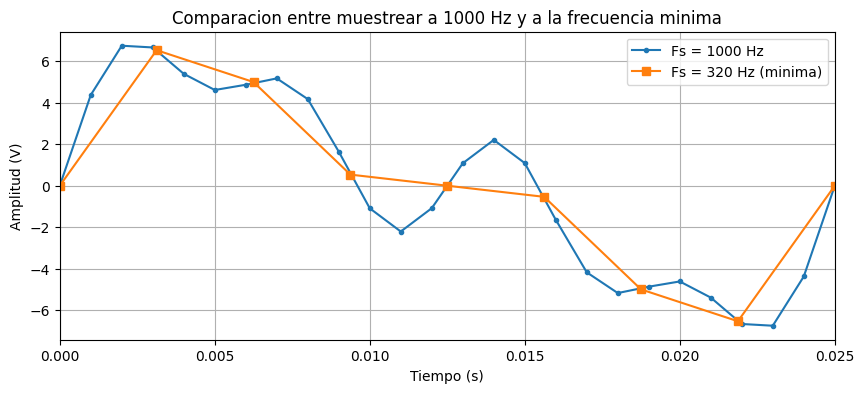

In [4]:
# Muestreamos la misma señal a la frecuencia minima de Nyquist
tm = np.arange(0, 10*Tp, 1/Fs_min)
xm = A1*np.sin(2*np.pi*f1*tm) + A2*np.sin(2*np.pi*f2*tm) + A3*np.sin(2*np.pi*f3*tm)

# Valores de la componente de 160 Hz cuando se muestrea a 320 Hz
comp160 = A3*np.sin(2*np.pi*f3*tm)
print('Primeras muestras de la componente de 160 Hz a 320 Hz:', np.round(comp160[:5], 4))

# Comparacion de las dos señales en un periodo
plt.figure(figsize=(10, 4))
plt.plot(t, x, marker='o', markersize=3, label='Fs = 1000 Hz')
plt.plot(tm, xm, marker='s', label='Fs = 320 Hz (minima)')
plt.xlim(0, Tp)
plt.title('Comparacion entre muestrear a 1000 Hz y a la frecuencia minima')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend()
plt.grid()
plt.show()

Aca se construyo una señal sumando tres senoidales de 40, 80 y 160 Hz con amplitudes de 5, 3 y 2 V. Como 80 y 160 Hz son multiplos de 40 Hz la señal resultante es periodica con el periodo de la componente mas lenta es decir 0.025 s. Eso se ve en la primera grafica, donde la misma forma se repite 10 veces en 0.25 s. Esto se parece a lo que pasa con muchas bioseñales por ejemplo el ECG que no es una sola onda sino la superposición de varias componentes de diferente frecuencia que juntas dan la forma de la onda P, el complejo QRS y la onda T.

Por el teorema de Nyquist la frecuencia de muestreo minima es el doble de la frecuencia mas alta que tenga la señal, en este caso 2 x 160 = 320 Hz. Pero en la tercera grafica se ve que muestrear justo en ese limite no es suficiente. A 320 Hz las muestras de la componente de 160 Hz caen en sus cruces por cero, entonces esa componente practicamente desaparece y la señal pierde detalles de su forma. Por eso en la practica se muestrea bastante por encima del minimo. Aqui se uso 1000 Hz, que da unas 6 muestras por ciclo de la componente mas rapida y permite ver bien la forma de la señal como en la segunda grafica donde se distinguen las tres componentes y su suma.

## Punto 2
Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal). (10%)

Numero de puntos de la DFT: 250
Resolucion en frecuencia (Fs/N): 4.0 Hz


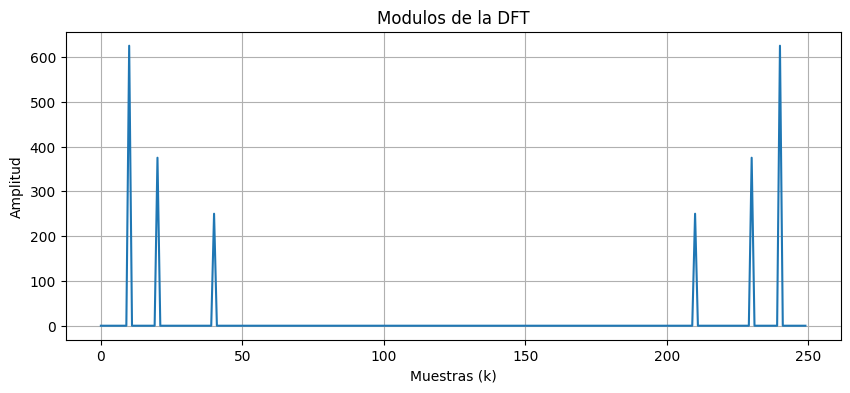

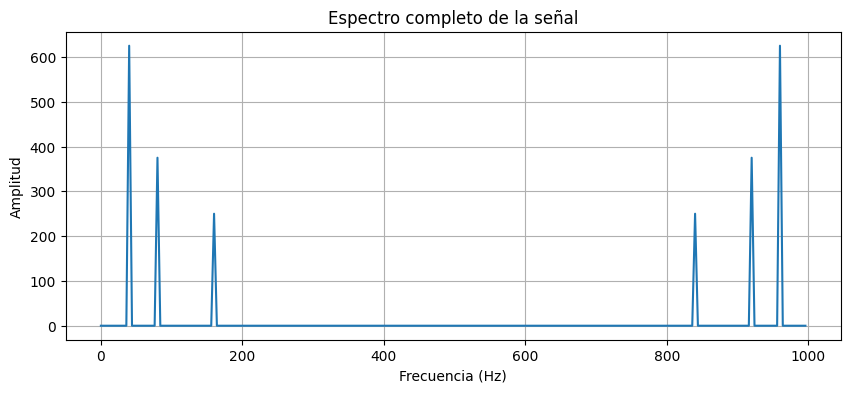

In [5]:
# Transformada discreta de Fourier de la señal (con la FFT)
X = np.fft.fft(x)

N = len(X)   # numero de puntos de la DFT (igual al numero de muestras)
print('Numero de puntos de la DFT:', N)
print('Resolucion en frecuencia (Fs/N):', Fs/N, 'Hz')

# Modulo de la DFT contra el indice k (como en la guia)
plt.figure(figsize=(10, 4))
plt.plot(abs(X))
plt.title('Modulos de la DFT')
plt.xlabel('Muestras (k)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

# Eje de frecuencia en Hz: F = k*Fs/N
F = np.arange(0, N)*Fs/N

plt.figure(figsize=(10, 4))
plt.plot(F, abs(X))
plt.title('Espectro completo de la señal')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

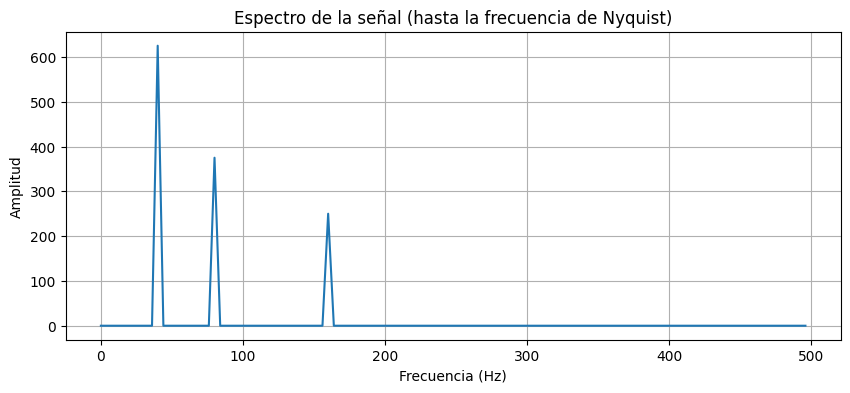

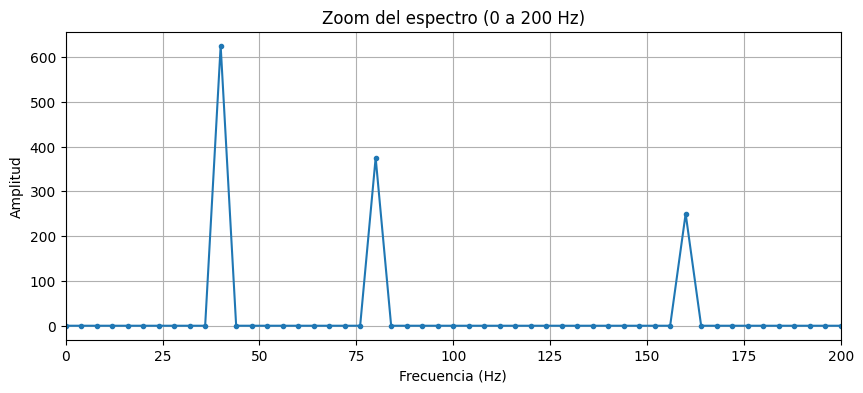

Pico en 40.0 Hz -> |X(k)| = 625.0 -> amplitud = 5.0 V
Pico en 80.0 Hz -> |X(k)| = 375.0 -> amplitud = 3.0 V
Pico en 160.0 Hz -> |X(k)| = 250.0 -> amplitud = 2.0 V


In [6]:
# Solo la mitad del espectro (hasta la frecuencia de Nyquist = Fs/2)
Nmitad = int(np.ceil(N/2))
Fmitad = np.arange(0, Nmitad)*Fs/N
Xmitad = X[0:Nmitad]

plt.figure(figsize=(10, 4))
plt.plot(Fmitad, abs(Xmitad))
plt.title('Espectro de la señal (hasta la frecuencia de Nyquist)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

# Zoom en la zona donde estan las componentes
plt.figure(figsize=(10, 4))
plt.plot(Fmitad, abs(Xmitad), marker='o', markersize=3)
plt.xlim(0, 200)
plt.title('Zoom del espectro (0 a 200 Hz)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.grid()
plt.show()

# Buscar los picos: puntos donde el modulo es mayor que 1 (el resto es casi cero)
picos = np.where(abs(Xmitad) > 1)[0]
for k in picos:
    amplitud_volt = 2*abs(Xmitad[k])/N   # se deshace el escalado: X(k) = N*A/2
    print('Pico en', Fmitad[k], 'Hz -> |X(k)| =', round(abs(Xmitad[k]), 2),
          '-> amplitud =', round(amplitud_volt, 2), 'V')

Cuando se calculo la DFT salieron 250 puntos que son las mismas muestras de la señal y en la primera grafica se ven tres picos al inicio y otros tres al final que son como un espejo. Esto pasa porque la señal es real y el modulo de la DFT es simetrico, entonces la segunda mitad no da informacion nueva y por eso se grafica solo hasta la frecuencia de Nyquist que es 500 Hz. Ya con el eje en Hz los picos quedan en 40, 80 y 160 Hz que son justo las frecuencias con las que armamos la señal. Las alturas tambien dan lo que dice la guia porque X(k) = N·ck, entonces la de 5 V da 625, la de 3 V da 375 y la de 2 V da 250, y al devolver ese escalado se recuperan las amplitudes originales. Los picos salen tan limpios porque la resolucion es de 4 Hz y las frecuencias son multiplos de 4 ademas de que se tomaron periodos completos, si no la energia se regaria a las frecuencias de al lado.

Lo interesante es que en el tiempo las tres ondas estaban mezcladas y no se podia saber que tenia la señal, pero en el espectro se ve clarito que frecuencias hay y cuanto aporta cada una. Eso es lo que se hace con las bioseñales, por ejemplo en un ECG se puede ver la frecuencia cardiaca y sus armonicos o si hay ruido de la red en 60 Hz, y en el EEG se miran las bandas alfa, beta, theta y delta que se relacionan con estados como el sueño o la concentracion.

## Punto 3
Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior. (10%)

In [7]:
# Transformada inversa de Fourier: del espectro X volvemos al tiempo
xr = np.fft.ifft(X)

# ifft devuelve numeros complejos, revisamos que tan grande es la parte imaginaria
print('Tipo de dato de la señal reconstruida:', xr.dtype)
print('Maximo valor de la parte imaginaria:', np.max(abs(np.imag(xr))))

# Nos quedamos con la parte real (la señal original era real)
xr_real = np.real(xr)

# Error entre la señal original y la reconstruida
error = x - xr_real
print('Error maximo entre la original y la reconstruida:', np.max(abs(error)))
print('¿Son practicamente iguales?:', np.allclose(x, xr_real))

# Comparamos las primeras 5 muestras
print('Primeras 5 muestras originales:     ', np.round(x[:5], 4))
print('Primeras 5 muestras reconstruidas:  ', np.round(xr_real[:5], 4))

Tipo de dato de la señal reconstruida: complex128
Maximo valor de la parte imaginaria: 1.6891834303775052e-15
Error maximo entre la original y la reconstruida: 3.552713678800501e-15
¿Son practicamente iguales?: True
Primeras 5 muestras originales:      [0.     4.3774 6.7514 6.6675 5.3951]
Primeras 5 muestras reconstruidas:   [0.     4.3774 6.7514 6.6675 5.3951]


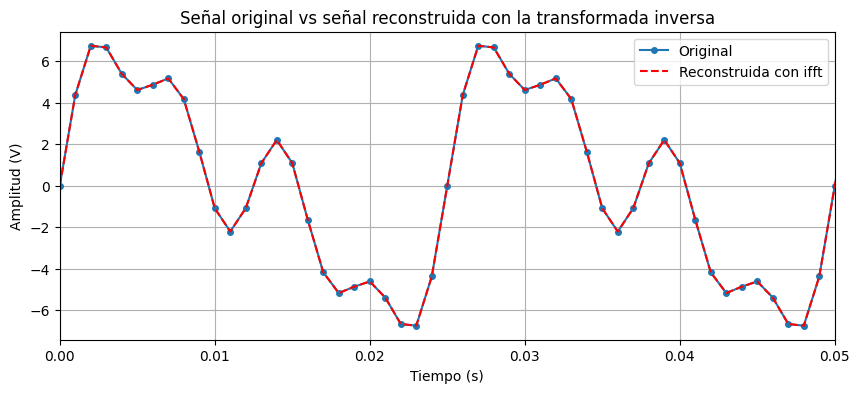

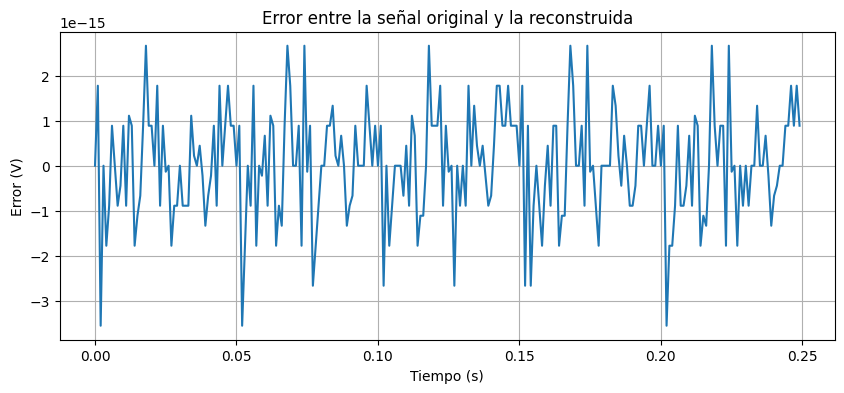

In [8]:
# Señal original y reconstruida una encima de la otra
plt.figure(figsize=(10, 4))
plt.plot(t, x, marker='o', markersize=4, label='Original')
plt.plot(t, xr_real, 'r--', label='Reconstruida con ifft')
plt.xlim(0, 2*Tp)   # dos periodos para que se vea mejor
plt.title('Señal original vs señal reconstruida con la transformada inversa')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend()
plt.grid()
plt.show()

# Error en cada muestra
plt.figure(figsize=(10, 4))
plt.plot(t, error)
plt.title('Error entre la señal original y la reconstruida')
plt.xlabel('Tiempo (s)')
plt.ylabel('Error (V)')
plt.grid()
plt.show()

La funcion para calcular la transformada inversa de Fourier en Python es np.fft.ifft, que hace el camino contrario a la fft. O sea recibe el espectro X(k) y devuelve la señal en el tiempo. Al aplicarla al espectro del punto anterior la señal reconstruida sale de tipo complejo, pero la parte imaginaria es de 10^-15 que es practicamente cero y solo son errores de redondeo del computador, por eso nos quedamos con la parte real. En la grafica la señal reconstruida queda exactamente encima de la original y las primeras muestras son iguales. El error maximo tambien es del orden de 10^-15, entonces se puede decir que se recupero la señal completa sin perder nada de informacion.

Esto es importante porque demuestra que pasar al dominio de la frecuencia y devolverse no daña la señal. Entonces uno puede hacer cosas en el espectro como quitar el ruido de 60 Hz o la deriva de la linea base en un ECG y despues volver al tiempo con la ifft.

## Punto 4
¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué? (10%)

F1 = np.fft.fft(x);
F2 = np.zeros((len(F1)));
F2[9:13] = F1[9:13];
xr = np.fft.ifft(F2);
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');
plt.show()

Extraiga de manera similar cada una de las componentes de la señal.

/tmp/ipykernel_3688/2252150436.py:4: ComplexWarning: Casting complex values to real discards the imaginary part
  F2[9:13] = F1[9:13];


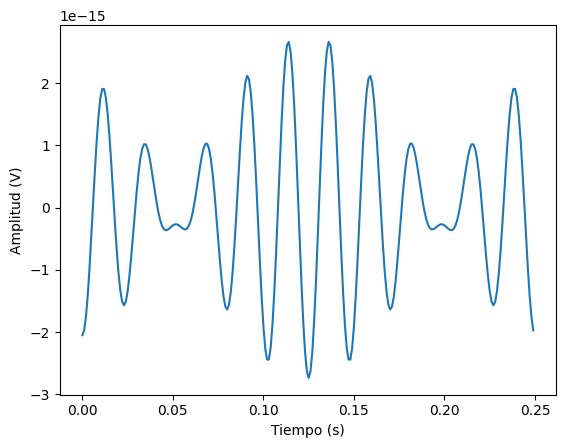

Frecuencias que deja pasar F2[9:13]: [36. 40. 44. 48.] Hz
Valor de F1 en 40 Hz (indice 10): (-0-625j)
Amplitud maxima de la señal filtrada: 2.7359675749729805e-15


In [9]:
# Codigo de la guia tal como esta
F1 = np.fft.fft(x);
F2 = np.zeros((len(F1)));
F2[9:13] = F1[9:13];
xr = np.fft.ifft(F2);
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');
plt.show()

# Que frecuencias corresponden a los indices 9 a 12
print('Frecuencias que deja pasar F2[9:13]:', np.arange(9, 13)*Fs/len(F1), 'Hz')

# Revisamos que tan grande quedo la señal filtrada
print('Valor de F1 en 40 Hz (indice 10):', np.round(F1[10], 2))
print('Amplitud maxima de la señal filtrada:', np.max(abs(np.real(xr))))

Indices del espejo: [238 239 240 241] -> [952. 956. 960. 964.] Hz


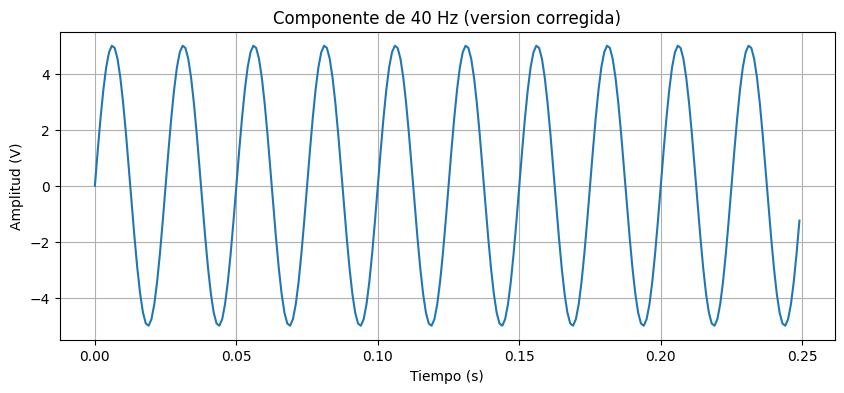

Amplitud maxima de la componente de 40 Hz: 4.99 V


In [10]:
N = len(F1)

# Espectro vacio pero de tipo complejo, para no perder la parte imaginaria
F2 = np.zeros(N, dtype=complex)

# Copiamos la banda de 36 a 48 Hz (indices 9 a 12)
F2[9:13] = F1[9:13]

# Copiamos tambien el espejo de esa banda (parte simetrica del espectro)
F2[N-12:N-8] = F1[N-12:N-8]
print('Indices del espejo:', np.arange(N-12, N-8), '->', np.arange(N-12, N-8)*Fs/N, 'Hz')

# Volvemos al tiempo
xr = np.fft.ifft(F2)

fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)', title='Componente de 40 Hz (version corregida)')
ax.grid()
plt.show()

print('Amplitud maxima de la componente de 40 Hz:', np.round(np.max(np.real(xr)), 2), 'V')

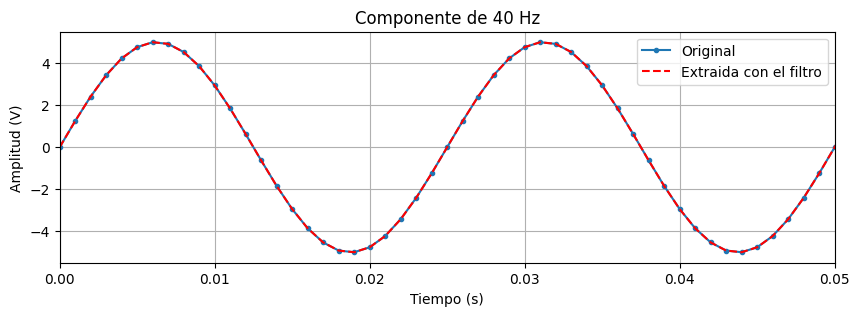

Componente 40 Hz -> amplitud maxima: 4.99 V, error maximo con la original: 2.9531932455029164e-14


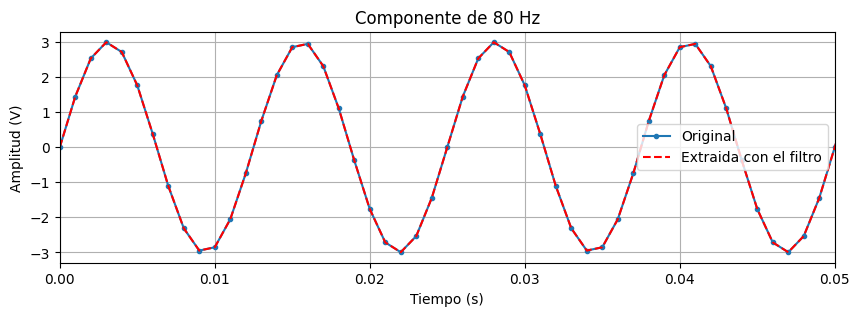

Componente 80 Hz -> amplitud maxima: 2.99 V, error maximo con la original: 3.4222551317787914e-14


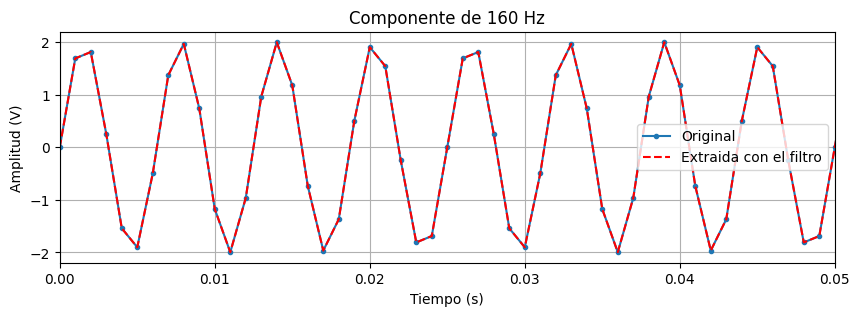

Componente 160 Hz -> amplitud maxima: 2.0 V, error maximo con la original: 4.790956669020728e-14
Error maximo entre la suma de las componentes y la señal original: 1.110549522325308e-13


In [11]:
# Funcion que deja pasar solo los indices de a hasta b-1 (y su espejo)
def filtro_fft(x, a, b):
    F1 = np.fft.fft(x)                      # espectro de la señal
    N = len(F1)
    F2 = np.zeros(N, dtype=complex)         # espectro vacio (complejo)
    F2[a:b] = F1[a:b]                       # banda que queremos
    F2[N-b+1:N-a+1] = F1[N-b+1:N-a+1]       # su espejo
    return np.real(np.fft.ifft(F2))         # volvemos al tiempo

# Cada componente con una banda de 4 indices alrededor de su frecuencia
x40  = filtro_fft(x, 9, 13)    # 36 a 48 Hz
x80  = filtro_fft(x, 19, 23)   # 76 a 88 Hz
x160 = filtro_fft(x, 39, 43)   # 156 a 168 Hz

# Graficamos cada componente extraida contra el seno original
componentes = [(x40, A1*np.sin(2*np.pi*f1*t), '40 Hz'),
               (x80, A2*np.sin(2*np.pi*f2*t), '80 Hz'),
               (x160, A3*np.sin(2*np.pi*f3*t), '160 Hz')]

for extraida, original, nombre in componentes:
    plt.figure(figsize=(10, 3))
    plt.plot(t, original, marker='o', markersize=3, label='Original')
    plt.plot(t, extraida, 'r--', label='Extraida con el filtro')
    plt.xlim(0, 2*Tp)
    plt.title('Componente de ' + nombre)
    plt.xlabel('Tiempo (s)')
    plt.ylabel('Amplitud (V)')
    plt.legend()
    plt.grid()
    plt.show()
    print('Componente', nombre, '-> amplitud maxima:', np.round(np.max(extraida), 2),
          'V, error maximo con la original:', np.max(abs(extraida - original)))

# Si sumamos las tres componentes deberia salir la señal completa
suma = x40 + x80 + x160
print('Error maximo entre la suma de las componentes y la señal original:', np.max(abs(suma - x)))

Si se puede decir que esas lineas aplican un filtro, porque lo que hacen es sacar el espectro de la señal, crear un espectro lleno de ceros y copiar solo los indices del 9 al 12, que con la resolucion de 4 Hz corresponden a 36, 40, 44 y 48 Hz. Todo lo demas queda en cero y al hacer la ifft se vuelve al tiempo solo con lo que habia en esa banda, o sea es un filtro pasabanda alrededor de 40 Hz. Pero al correr el codigo tal cual salio una señal de 10^-15 que es practicamente cero. Esto paso porque np.zeros crea un arreglo real, y como el coeficiente de un seno en la fft es imaginario puro (en 40 Hz dio -625j), Python boto la parte imaginaria y no quedo nada. Ademas el codigo solo copia la mitad positiva del espectro y no su espejo, entonces aunque se arregle lo de los complejos el seno saldria con la mitad de la amplitud. Por eso se corrigio creando el arreglo complejo y copiando tambien los indices simetricos (238 a 241), y ahi si salio el seno de 40 Hz con amplitud de 5 V.

Con esa misma idea se sacaron las tres componentes por separado y cada una quedo igualita al seno original con errores de 10^-14. Al sumarlas se recupera la señal completa, lo que muestra que la señal de verdad es la suma de esas tres frecuencias. Esto se relaciona con lo que se hace en bioseñales cuando uno quiere quedarse solo con una parte de la informacion. Por ejemplo en el EEG se puede aislar la banda alfa (8-13 Hz) para ver si la persona esta relajada, o en un ECG se puede quitar el ruido de 60 Hz de la red o la deriva de la linea base que causa la respiracion. Aca funciono perfecto porque cada componente estaba en una sola frecuencia y bien separada de las otras. En una señal fisiologica real las componentes se traslapan y el ruido no esta en un solo punto, entonces al cortar el espectro de forma tan brusca se podria quitar tambien informacion util de la señal y hay que escoger bien la banda.

## Punto 5
Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales construidas anteriormente.

El periodograma de Welch sirve para estimar como se reparte la potencia de una señal en las diferentes frecuencias, pero en vez de sacar una sola fft de toda la señal la parte en pedazos y promedia. Los pasos que sigue la funcion son:

1. Se escoge el ancho de la ventana (nperseg) y cuantas muestras se van a solapar las ventanas (noverlap). Con eso se calcula el paso, que es cuanto se corre la ventana cada vez (nperseg - noverlap), y cuantos segmentos caben en la señal.
2. Se crea la ventana de Hanning, que tiene forma de campana y va a cero en los bordes. Esto se hace para que al cortar la señal en pedazos no queden saltos bruscos en los extremos, porque esos saltos meten frecuencias que no existen (fuga espectral).
3. Se recorre la señal segmento por segmento. A cada pedazo se le quita su promedio para que no aparezca un pico falso en 0 Hz, y despues se multiplica por la ventana.
4. A cada segmento ventaneado se le saca la DFT con la fft y se calcula su periodograma, que es el modulo al cuadrado dividido por fs y por la suma de la ventana al cuadrado. Esa division es para que quede como densidad espectral de potencia en V²/Hz y para compensar la energia que se pierde al ventanear.
5. Se promedian los periodogramas de todos los segmentos. Este es el paso clave de Welch, porque al promediar se reduce la varianza y el espectro sale mas suave y confiable que con una sola ventana.
6. Como la señal es real el espectro es simetrico, entonces solo se deja la mitad hasta la frecuencia de Nyquist y se multiplica por 2 para no perder la potencia de la otra mitad (menos en 0 Hz y en Nyquist, que no tienen espejo).
7. Se arma el eje de frecuencias con k·fs/nperseg, entonces la resolucion depende del ancho de la ventana y no del largo total de la señal.

In [12]:
def welch_manual(senal, fs, nperseg, noverlap):
    senal = np.asarray(senal, dtype=float).ravel()   # aseguramos un vector de numeros

    # Paso 1: cuanto se corre la ventana y cuantos segmentos caben
    paso = nperseg - noverlap
    nseg = (len(senal) - noverlap) // paso

    # Paso 2: ventana de Hanning (forma de campana que va a cero en los bordes)
    n = np.arange(nperseg)
    w = 0.5 - 0.5*np.cos(2*np.pi*n/nperseg)

    periodogramas = []
    for i in range(nseg):
        # Paso 3: tomamos el segmento, le quitamos el promedio y lo multiplicamos por la ventana
        inicio = i*paso
        segmento = senal[inicio : inicio + nperseg]
        segmento = segmento - np.mean(segmento)
        segmento_v = segmento * w

        # Paso 4: DFT del segmento y su periodograma (densidad de potencia en V^2/Hz)
        X = np.fft.fft(segmento_v)
        P = abs(X)**2 / (fs * np.sum(w**2))
        periodogramas.append(P)

    # Paso 5: promediamos los periodogramas de todos los segmentos
    Pxx = np.mean(periodogramas, axis=0)

    # Paso 6: nos quedamos con la mitad (hasta Nyquist) y multiplicamos por 2
    nmitad = nperseg//2 + 1
    Pxx = Pxx[:nmitad]
    Pxx[1:] = 2*Pxx[1:]
    if nperseg % 2 == 0:
        Pxx[-1] = Pxx[-1]/2      # la frecuencia de Nyquist no tiene espejo

    # Paso 7: eje de frecuencias
    f = np.arange(nmitad) * fs / nperseg

    return f, Pxx, nseg

Numero de segmentos usados: 4
Resolucion en frecuencia: 10.0 Hz


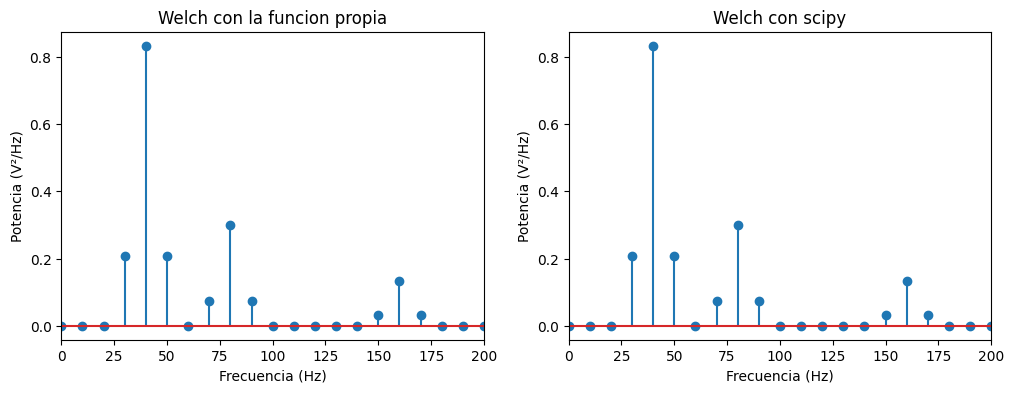

Diferencia maxima entre la funcion propia y scipy: 5.551115123125783e-17
Potencia en 40 Hz: 0.8333 V²/Hz
Potencia en 80 Hz: 0.3 V²/Hz
Potencia en 160 Hz: 0.1333 V²/Hz


In [13]:
from scipy.signal import welch as pwelch

# Parametros de la ventana (como en la guia: solapamiento del 50%)
nperseg = 100                  # ancho de la ventana (0.1 s)
noverlap = int(nperseg/2)      # solapamiento de las ventanas

# Welch con nuestra funcion
f_m, P_m, nseg = welch_manual(x, Fs, nperseg, noverlap)
print('Numero de segmentos usados:', nseg)
print('Resolucion en frecuencia:', Fs/nperseg, 'Hz')

# Welch con la libreria (en versiones nuevas de scipy la ventana se llama 'hann')
f_l, P_l = pwelch(x, Fs, 'hann', nperseg, noverlap)

# Graficamos las dos (como en la guia, con stem)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].stem(f_m, P_m)
ax[0].set(title='Welch con la funcion propia', xlabel='Frecuencia (Hz)', ylabel='Potencia (V²/Hz)')
ax[0].set_xlim(0, 200)
ax[1].stem(f_l, P_l)
ax[1].set(title='Welch con scipy', xlabel='Frecuencia (Hz)', ylabel='Potencia (V²/Hz)')
ax[1].set_xlim(0, 200)
plt.show()

# Comparacion numerica entre las dos
print('Diferencia maxima entre la funcion propia y scipy:', np.max(abs(P_m - P_l)))

# Potencia en las frecuencias de la señal
for fr in [40, 80, 160]:
    k = int(fr*nperseg/Fs)
    print('Potencia en', fr, 'Hz:', np.round(P_m[k], 4), 'V²/Hz')

Para esta señal tan limpia Welch no tiene mucha ventaja sobre la fft normal, pero con bioseñales si es muy util. Una señal real como el ECG o el EEG tiene ruido y cambia con el tiempo, porque el ritmo cardiaco varia latido a latido y la actividad cerebral cambia segun el estado de la persona. Entonces si se saca una sola fft el espectro sale muy ruidoso y con picos que no son reales. Al promediar varias ventanas el ruido se cancela y queda mas claro cuales frecuencias si tienen potencia de verdad. Por eso Welch se usa mucho por ejemplo para ver la potencia de las bandas del EEG o en el analisis de variabilidad de la frecuencia cardiaca. Lo importante es escojer bien el ancho de la ventana: si es muy corta se pierde resolucion, y si es muy larga quedan pocos segmentos para promediar.

## Punto 6
El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventana) (25%). Compare el método de la librería con la función creada en el punto anterior.

cargar y graficar la señal

Variables dentro del archivo: dict_keys(['__header__', '__version__', '__globals__', 'ECG'])
Numero de muestras: 1250
Duracion de la señal: 5.0 s


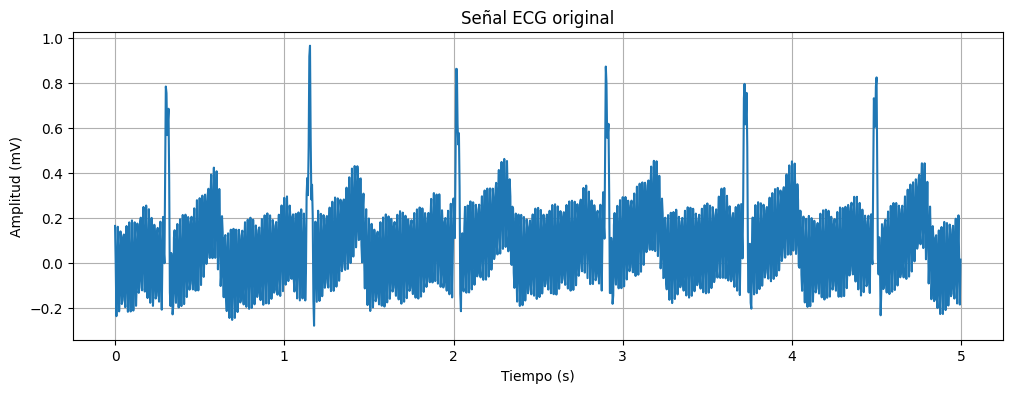

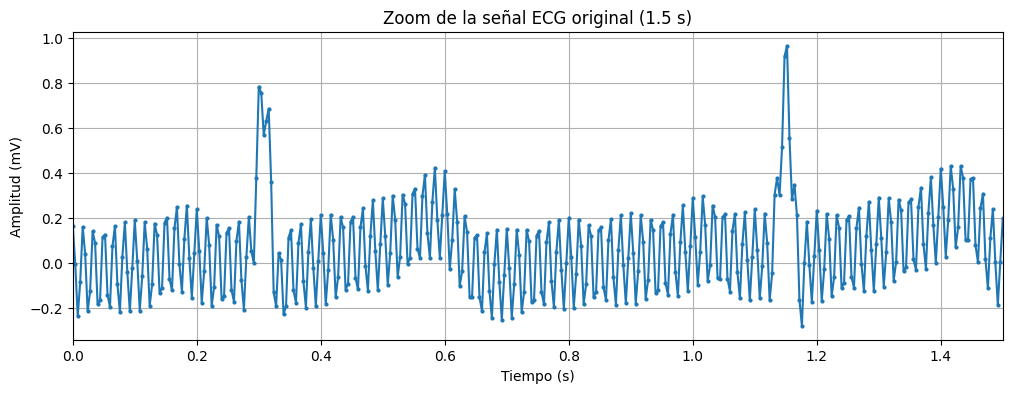

In [14]:
import scipy.io as sio
from scipy.signal import welch as pwelch

# Cargamos el archivo .mat
datos = sio.loadmat('senecg.mat')
print('Variables dentro del archivo:', datos.keys())

ecg = datos['ECG'].ravel()     # la señal viene como columna, la volvemos vector
fs_ecg = 250                   # frecuencia de muestreo (Hz)
N_ecg = len(ecg)
t_ecg = np.arange(N_ecg)/fs_ecg   # vector de tiempo

print('Numero de muestras:', N_ecg)
print('Duracion de la señal:', N_ecg/fs_ecg, 's')

# Señal completa
plt.figure(figsize=(12, 4))
plt.plot(t_ecg, ecg)
plt.title('Señal ECG original')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.grid()
plt.show()

# Zoom a 1.5 s para ver mejor un latido
plt.figure(figsize=(12, 4))
plt.plot(t_ecg, ecg, marker='o', markersize=2)
plt.xlim(0, 1.5)
plt.title('Zoom de la señal ECG original (1.5 s)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.grid()
plt.show()

Welch con diferentes anchos de ventana

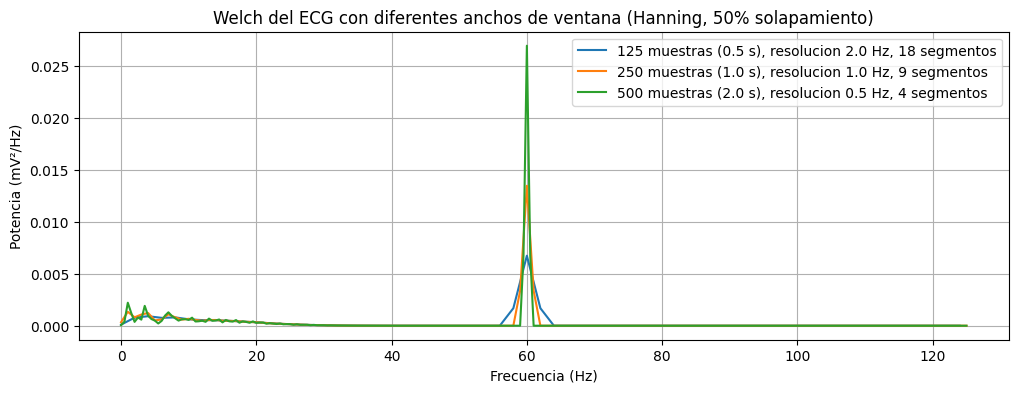

In [15]:
# Probamos tres anchos de ventana, todos con solapamiento del 50%
anchos = [125, 250, 500]    # 0.5 s, 1 s y 2 s

plt.figure(figsize=(12, 4))
for nps in anchos:
    f_w, P_w = pwelch(ecg, fs_ecg, 'hann', nps, int(nps/2))
    nseg = (N_ecg - int(nps/2)) // (nps - int(nps/2))
    plt.plot(f_w, P_w, label=f'{nps} muestras ({nps/fs_ecg} s), resolucion {fs_ecg/nps} Hz, {nseg} segmentos')
plt.title('Welch del ECG con diferentes anchos de ventana (Hanning, 50% solapamiento)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (mV²/Hz)')
plt.legend()
plt.grid()
plt.show()

Welch con la ventana escogida

Resolucion en frecuencia: 0.5 Hz
Frecuencia con mas potencia: 60.0 Hz


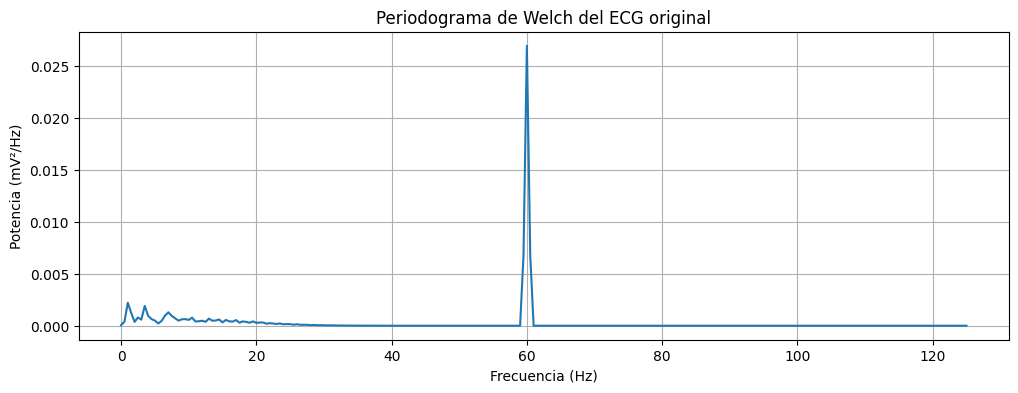

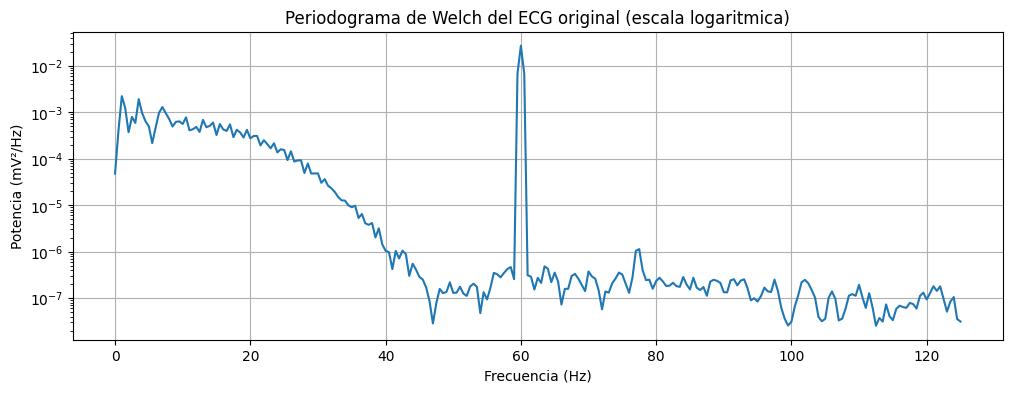

In [16]:
# Parametros escogidos
nperseg_ecg = 500                     # ventana de 2 s (unos 2 latidos)
noverlap_ecg = int(nperseg_ecg/2)     # 50% de solapamiento

f_ecg, P_ecg = pwelch(ecg, fs_ecg, 'hann', nperseg_ecg, noverlap_ecg)

print('Resolucion en frecuencia:', fs_ecg/nperseg_ecg, 'Hz')
print('Frecuencia con mas potencia:', f_ecg[np.argmax(P_ecg)], 'Hz')

# Escala normal
plt.figure(figsize=(12, 4))
plt.plot(f_ecg, P_ecg)
plt.title('Periodograma de Welch del ECG original')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (mV²/Hz)')
plt.grid()
plt.show()

# Escala logaritmica: deja ver mejor el contenido propio del ECG (bajas frecuencias)
plt.figure(figsize=(12, 4))
plt.semilogy(f_ecg, P_ecg)
plt.title('Periodograma de Welch del ECG original (escala logaritmica)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (mV²/Hz)')
plt.grid()
plt.show()

En la señal original se ven 6 complejos QRS en los 5 segundos separados mas o menos 0.84 s lo que da una frecuencia cardiaca como de 71 latidos por minuto que esta dentro de lo normal para un adulto en reposo (60 a 100 lpm). Pero encima de toda la señal hay una oscilacion rapidaque casi no deja ver la onda P ni la onda T. En el zoom se ve que se repite unas 9 veces cada 0.15 s osea que esta mas o menos como en 60 Hz. Solo el QRS se distingue bien porque es la onda mas grande que corresponde a la despolarizacion de los ventriculos pero si uno quisiera medir el intervalo PR o mirar la forma del segmento ST seria muy dificil con ese ruido.

El periodograma de Welch confirma que la frecuencia con mas potencia es exactamente 60 Hz y ese pico es como 10 veces mas grande que todo el ECG. Esto es ruido de la red electrica que se mete por los cables, por una mala conexion de los electrodos o por la tierra del equipo. En la escala logaritmica se ve que la potencia del ECG esta casi toda entre 0 y 40 Hz y despues cae hasta quedar en el piso de ruido. las ondas P y T son lentas y estan en las frecuencias bajas, el QRS por ser mas rapido aporta hasta unos 40 Hz, y los picos cerca de 1 Hz tienen que ver con el ritmo cardiaco. Como el pico de 60 Hz esta lejos de donde esta la informacion del corazón, si es necesario quitarlo.

Para escoger la ventana se probaron tres anchos con ventana Hanning. Con 0.5 s la ventana es mas corta que un latido y la resolucion es de 2 Hz entonces el pico de 60 Hz sale ancho y bajito y no se ve bien el detalle de las bajas frecuencias. Con 2 s (500 muestras) caben mas o menos dos ciclos cardiacos completos y la resolucion es de 0.5 Hz suficiente para ver la frecuencia cardiaca y un pico de ruido bien definido por eso se escogio ese. La desventaja es que como la señal solo dura 5 s quedan pocos segmentos para promediar (4) y si se usara una ventana mas larga quedarian casi ninguno. El solapamiento fue de 50% porque la ventana de Hanning se va a cero en los bordes y esa parte de la señal casi no se tiene en cuenta entonces al solapar la mitad se aprovechan esos datos y salen mas segmentos para que el promedio sea mas confiable.

quitar el ruido de 60 Hz con la FFT y volver con la inversa

Frecuencias que se eliminan: [59.  59.2 59.4 59.6 59.8 60.  60.2 60.4 60.6 60.8 61. ] Hz
Y su espejo: [189.  189.2 189.4 189.6 189.8 190.  190.2 190.4 190.6 190.8 191. ] Hz
Maximo de la parte imaginaria: 1.3359448010614673e-16


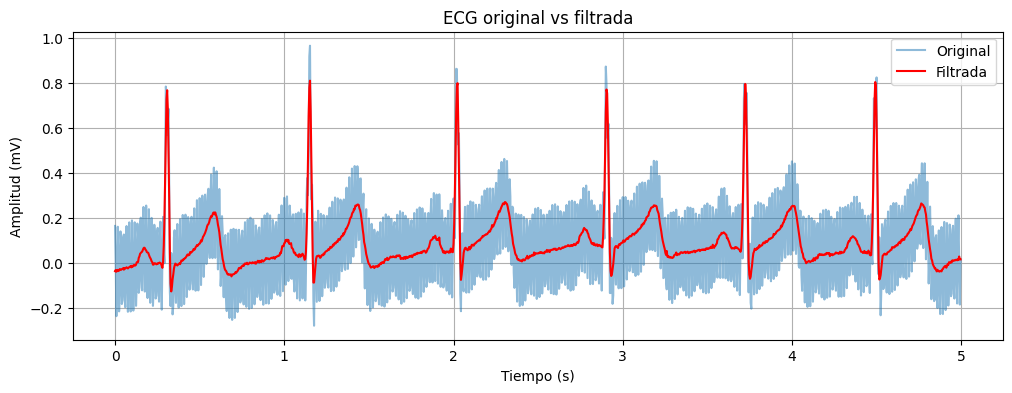

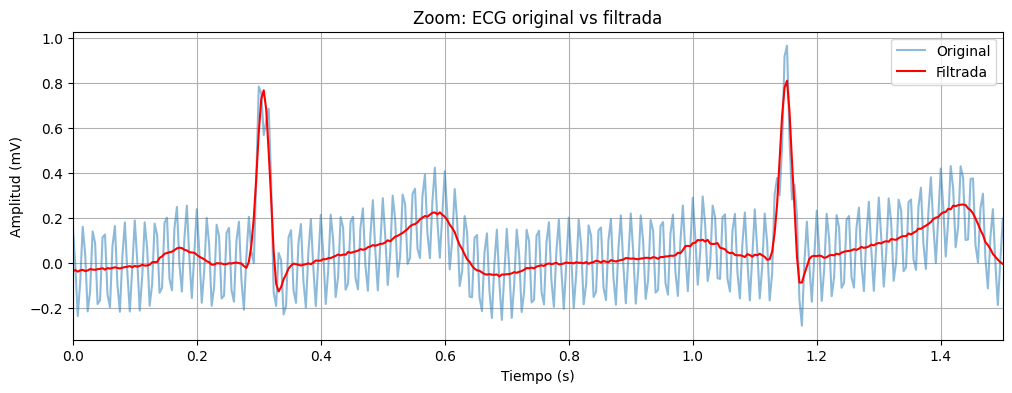

In [17]:
# FFT de la señal completa
F_ecg = np.fft.fft(ecg)
frec = np.arange(N_ecg)*fs_ecg/N_ecg      # eje de frecuencias (resolucion 0.2 Hz)

# Indices de la banda que queremos eliminar: 59 a 61 Hz
a = int(59*N_ecg/fs_ecg)
b = int(61*N_ecg/fs_ecg) + 1
print('Frecuencias que se eliminan:', frec[a:b], 'Hz')
print('Y su espejo:', frec[N_ecg-b+1:N_ecg-a+1], 'Hz')

# Copiamos el espectro y ponemos en cero la banda de 60 Hz y su espejo
F_filt = F_ecg.copy()
F_filt[a:b] = 0
F_filt[N_ecg-b+1:N_ecg-a+1] = 0

# Transformada inversa para volver al tiempo
ecg_f = np.fft.ifft(F_filt)
print('Maximo de la parte imaginaria:', np.max(abs(np.imag(ecg_f))))
ecg_f = np.real(ecg_f)

# Comparamos en el tiempo
plt.figure(figsize=(12, 4))
plt.plot(t_ecg, ecg, alpha=0.5, label='Original')
plt.plot(t_ecg, ecg_f, 'r', label='Filtrada')
plt.title('ECG original vs filtrada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.legend()
plt.grid()
plt.show()

# Zoom a un latido
plt.figure(figsize=(12, 4))
plt.plot(t_ecg, ecg, alpha=0.5, label='Original')
plt.plot(t_ecg, ecg_f, 'r', label='Filtrada')
plt.xlim(0, 1.5)
plt.title('Zoom: ECG original vs filtrada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.legend()
plt.grid()
plt.show()

comprobar con el periodograma

Potencia en 60 Hz antes de filtrar: 0.02698853559865274
Potencia en 60 Hz despues de filtrar: 2.842166325749398e-10


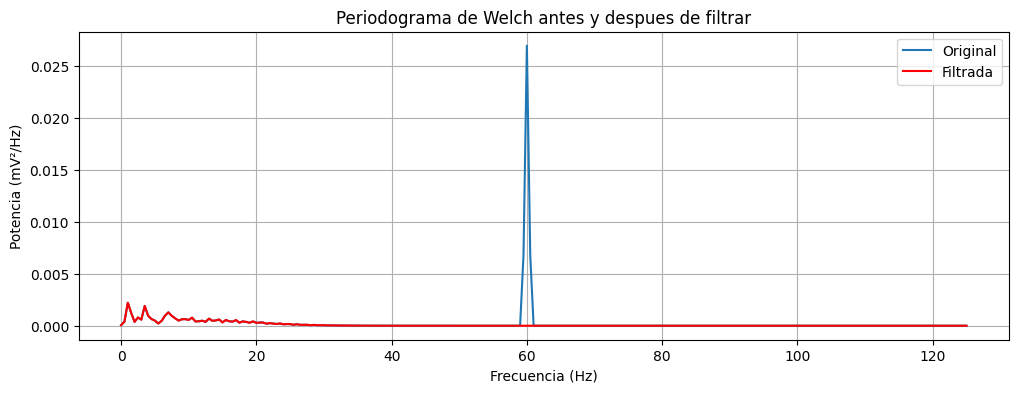

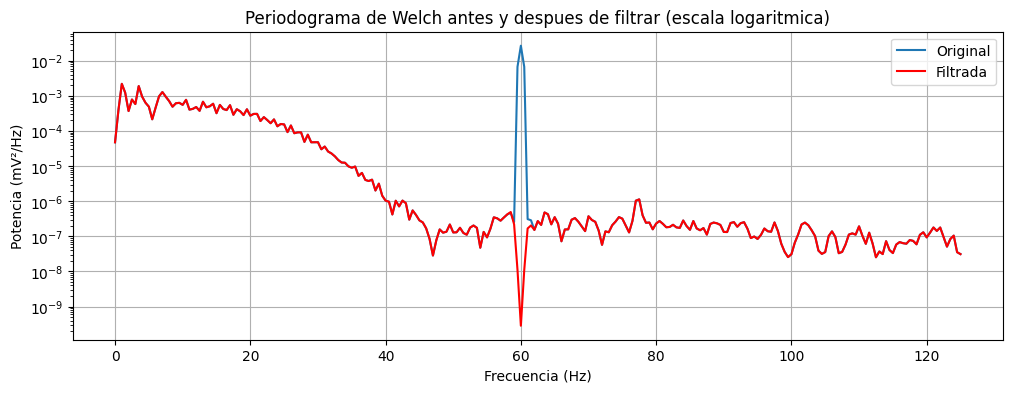

In [18]:
# Welch de la señal filtrada con los mismos parametros
f_f, P_f = pwelch(ecg_f, fs_ecg, 'hann', nperseg_ecg, noverlap_ecg)

i60 = np.argmin(abs(f_ecg - 60))
print('Potencia en 60 Hz antes de filtrar:', P_ecg[i60])
print('Potencia en 60 Hz despues de filtrar:', P_f[i60])

plt.figure(figsize=(12, 4))
plt.plot(f_ecg, P_ecg, label='Original')
plt.plot(f_f, P_f, 'r', label='Filtrada')
plt.title('Periodograma de Welch antes y despues de filtrar')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (mV²/Hz)')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.semilogy(f_ecg, P_ecg, label='Original')
plt.semilogy(f_f, P_f, 'r', label='Filtrada')
plt.title('Periodograma de Welch antes y despues de filtrar (escala logaritmica)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Potencia (mV²/Hz)')
plt.legend()
plt.grid()
plt.show()

Para quitar el ruido se puso en cero la banda de 59 a 61 Hz en la fft y tambien su espejo en 189 a 191 Hz, y despues se volvio al tiempo con la ifft. El cambio fue que la oscilacion desaparecio y ya se ven bien todas las ondas del ciclo cardiaco, la onda P pequeña antes del QRS que es la despolarizacion de las auriculas, el QRS y despues la onda T que es la repolarizacion de los ventriculos. El QRS bajo un poquito de amplitud pero es porque en la original el ruido se le sumaba encima y lo hacia ver mas alto, la forma del latido se conservo igual. Ahora si se podrian medir cosas como el intervalo PR o el segmento ST que son importantes clinicamente por ejemplo para ver problemas de conduccion o isquemia.

En el periodograma se ve que funciono porque la potencia en 60 Hz paso de 0.027 a 10^-10 practicamente nada y en la escala logaritmica queda un hueco justo en esa frecuencia. Lo mas importante es que el resto del espectro entre 0 y 40 Hz quedo igualito a la señak original la curva roja queda encima de la azul, entonces no se perdio informacion del corazon. Esto funciono tan bien porque el ruido estaba en una sola frecuencia y lejos de la banda del ECG. Si el ruido estuviera mezclado con las frecuencias del corazon no se podria quitar tan facil sin dañar la señal.

librería vs función propia

Segmentos usados: 4
Diferencia maxima (señal original): 2.6020852139652106e-18
Diferencia maxima (señal filtrada): 1.0842021724855044e-18


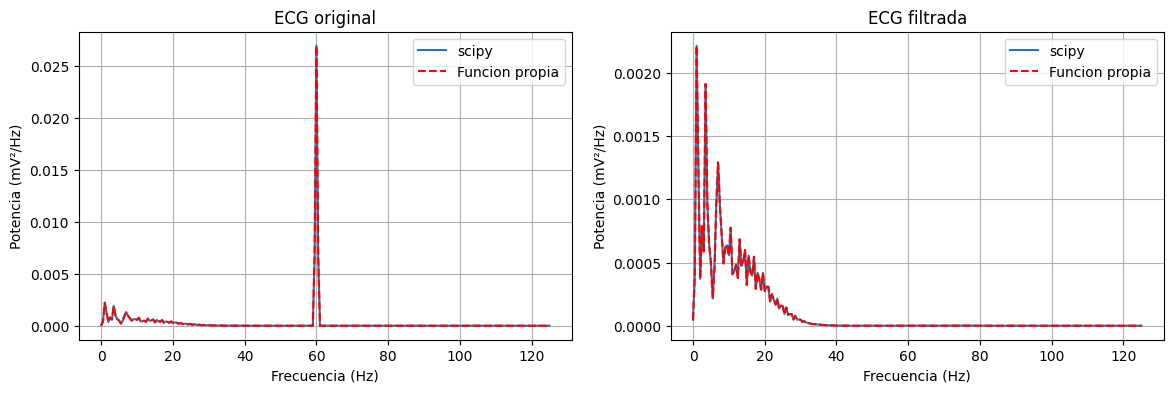

In [19]:
# Welch con nuestra funcion del punto 5, mismos parametros
f_m1, P_m1, nseg1 = welch_manual(ecg, fs_ecg, nperseg_ecg, noverlap_ecg)
f_m2, P_m2, nseg2 = welch_manual(ecg_f, fs_ecg, nperseg_ecg, noverlap_ecg)

print('Segmentos usados:', nseg1)
print('Diferencia maxima (señal original):', np.max(abs(P_m1 - P_ecg)))
print('Diferencia maxima (señal filtrada):', np.max(abs(P_m2 - P_f)))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(f_ecg, P_ecg, label='scipy')
ax[0].plot(f_m1, P_m1, 'r--', label='Funcion propia')
ax[0].set(title='ECG original', xlabel='Frecuencia (Hz)', ylabel='Potencia (mV²/Hz)')
ax[0].legend(); ax[0].grid()
ax[1].plot(f_f, P_f, label='scipy')
ax[1].plot(f_m2, P_m2, 'r--', label='Funcion propia')
ax[1].set(title='ECG filtrada', xlabel='Frecuencia (Hz)', ylabel='Potencia (mV²/Hz)')
ax[1].legend(); ax[1].grid()
plt.show()

Al comparar el periodograma de scipy con la funcion que hicimos en el punto 5 dieron practicamente iguales en las dos señales con diferencias de 10^-18 que son solo errores de redondei y en las graficas las curvas quedan una encima de la otra. Esto pasa porque las dos hacen exactamente lo mismo parten la señal en 4 segmentos de 2 s con 50% de solapamiento les quitan el promedio, los multiplican por la ventana de Hanning sacan la fft y promedian. La ventaja de la libreria es que ya esta probada y tiene mas opciones como otras ventanas o promediar con la mediana pero hacer la funcion a mano sirve para entender que hay detras y saber como escojer los parametros. En el espectro de la señal filtrada tambien se ve mejor el contenido del ECG con los picos mas altod cerca de 1 Hz que tienen que ver con la frecuencia cardiaca y luego la potencia bajando hasta los 40 Hz que es donde estan las ondas P, QRS y T.

## Punto 7
Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto 1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventana) (25%)

                           Rhythm  PatientAge Gender  VentricularRate  \
FileName                                                                
MUSE_20180209_131330_43000     SR          62   MALE               68   
MUSE_20180112_170307_12000   AFIB          65   MALE               68   

                            AtrialRate  
FileName                                
MUSE_20180209_131330_43000          68  
MUSE_20180112_170307_12000         416  
Muestras por señal: 5000 -> duracion: 10.0 s


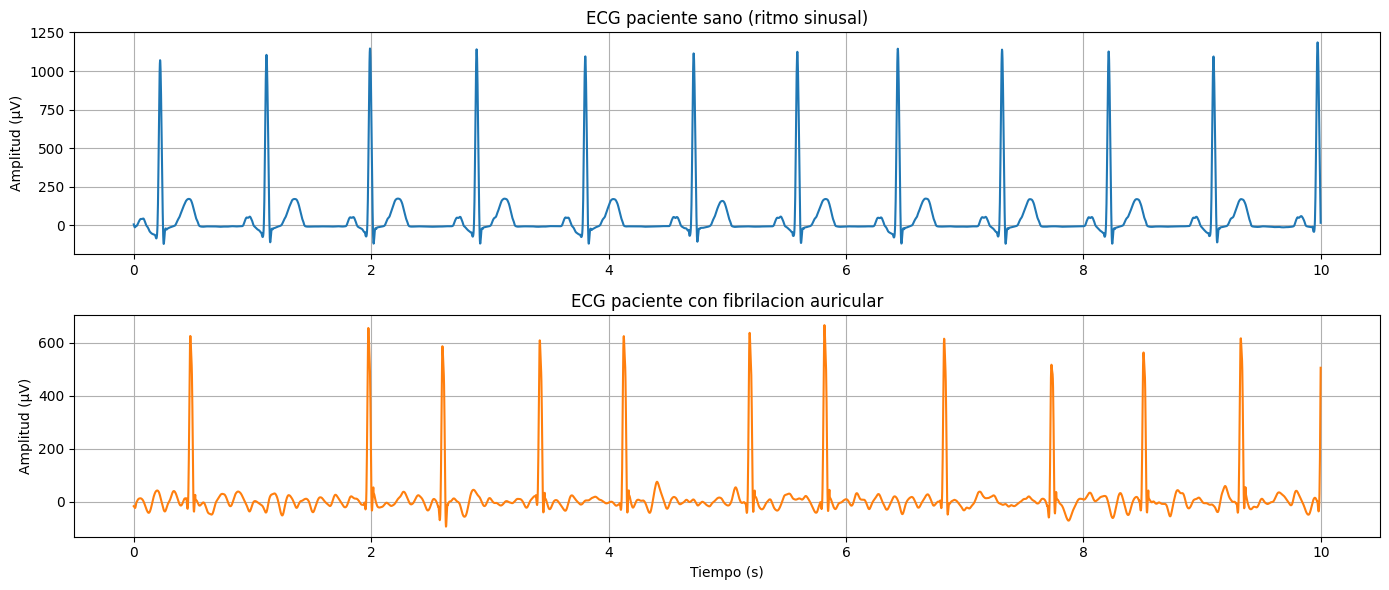

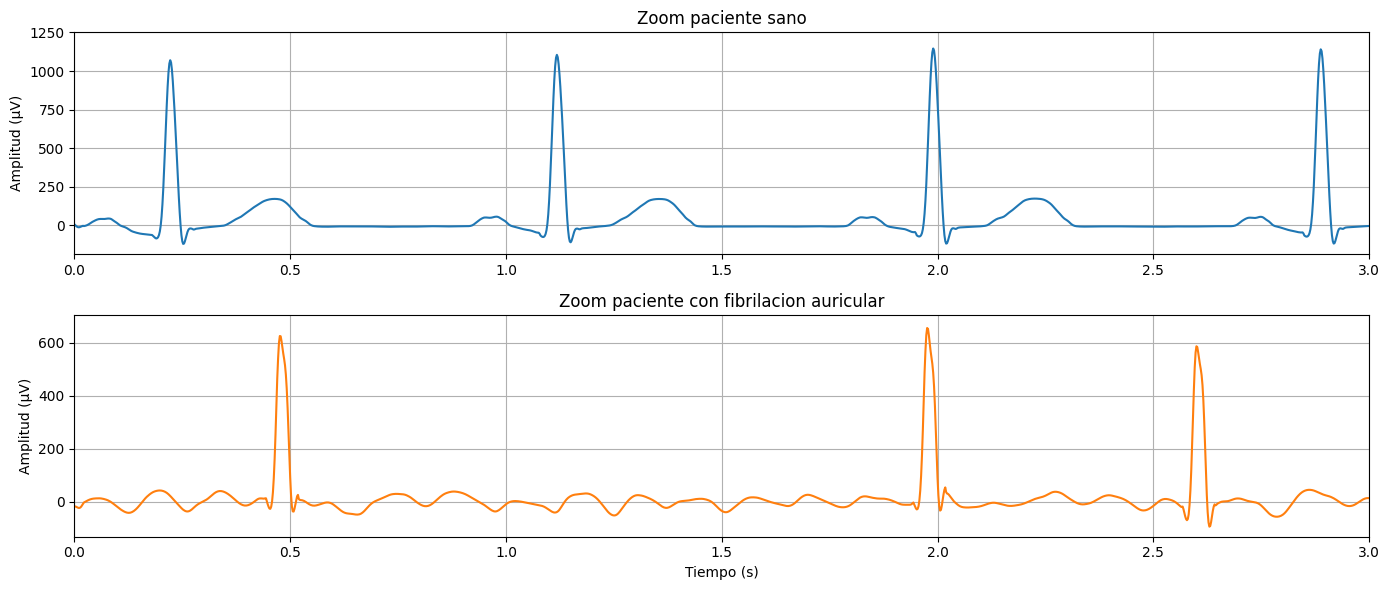

Sano: 12 latidos, RR promedio = 0.886 s, desviacion = 0.019 s, variacion = 2.2 %, FC = 67.7 lpm
AFIB: 11 latidos, RR promedio = 0.885 s, desviacion = 0.247 s, variacion = 27.9 %, FC = 67.8 lpm


In [20]:
import pandas as pd
from scipy.signal import welch as pwelch, find_peaks

fs7 = 500   # frecuencia de muestreo de la base Chapman (Hz)

# Registros escogidos
sano = 'MUSE_20180209_131330_43000'   # ritmo sinusal normal
afib = 'MUSE_20180112_170307_12000'   # fibrilacion auricular

# Informacion de los pacientes desde Diagnostics
diag = pd.read_excel('Diagnostics.xlsx').set_index('FileName')
print(diag.loc[[sano, afib], ['Rhythm', 'PatientAge', 'Gender', 'VentricularRate', 'AtrialRate']])

# Cargamos la derivacion II (columna 1), como en el proyecto 1
ecg_sano = np.loadtxt(sano + '.csv', delimiter=',')[:, 1]
ecg_afib = np.loadtxt(afib + '.csv', delimiter=',')[:, 1]
t7 = np.arange(len(ecg_sano))/fs7
print('Muestras por señal:', len(ecg_sano), '-> duracion:', len(ecg_sano)/fs7, 's')

# Señales completas
fig, ax = plt.subplots(2, 1, figsize=(14, 6))
ax[0].plot(t7, ecg_sano)
ax[0].set(title='ECG paciente sano (ritmo sinusal)', ylabel='Amplitud (µV)')
ax[1].plot(t7, ecg_afib, color='tab:orange')
ax[1].set(title='ECG paciente con fibrilacion auricular', xlabel='Tiempo (s)', ylabel='Amplitud (µV)')
for a in ax: a.grid()
plt.tight_layout()
plt.show()

# Zoom de 3 s para ver las ondas
fig, ax = plt.subplots(2, 1, figsize=(14, 6))
ax[0].plot(t7, ecg_sano); ax[0].set_xlim(0, 3)
ax[0].set(title='Zoom paciente sano', ylabel='Amplitud (µV)')
ax[1].plot(t7, ecg_afib, color='tab:orange'); ax[1].set_xlim(0, 3)
ax[1].set(title='Zoom paciente con fibrilacion auricular', xlabel='Tiempo (s)', ylabel='Amplitud (µV)')
for a in ax: a.grid()
plt.tight_layout()
plt.show()

# Intervalos RR (tiempo entre latidos) para ver que tan regular es el ritmo
for nombre, s in [('Sano', ecg_sano), ('AFIB', ecg_afib)]:
    picos, _ = find_peaks(s, height=0.5*np.max(s), distance=int(0.3*fs7))   # picos R
    rr = np.diff(picos)/fs7
    print(f'{nombre}: {len(picos)} latidos, RR promedio = {rr.mean():.3f} s, '
          f'desviacion = {rr.std():.3f} s, variacion = {100*rr.std()/rr.mean():.1f} %, '
          f'FC = {60/rr.mean():.1f} lpm')

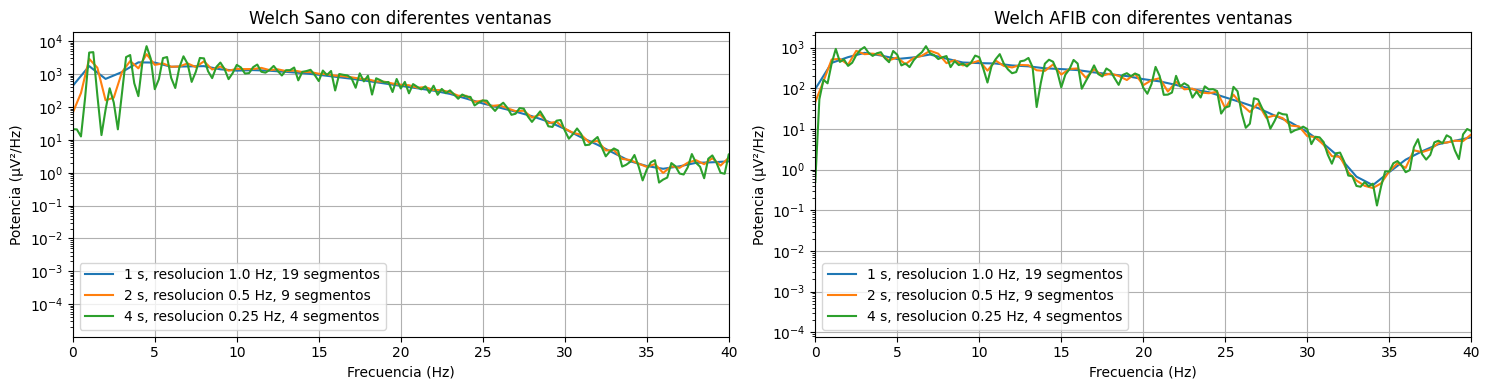

In [21]:
# Tres anchos de ventana, todos con Hanning y 50% de solapamiento
anchos7 = [500, 1000, 2000]    # 1 s, 2 s y 4 s

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for k, (nombre, s) in enumerate([('Sano', ecg_sano), ('AFIB', ecg_afib)]):
    for nps in anchos7:
        f_w, P_w = pwelch(s, fs7, 'hann', nps, int(nps/2))
        nseg = (len(s) - int(nps/2)) // (nps - int(nps/2))
        ax[k].semilogy(f_w, P_w, label=f'{nps/fs7:.0f} s, resolucion {fs7/nps} Hz, {nseg} segmentos')
    ax[k].set(title=f'Welch {nombre} con diferentes ventanas', xlabel='Frecuencia (Hz)', ylabel='Potencia (µV²/Hz)')
    ax[k].set_xlim(0, 40)
    ax[k].legend(); ax[k].grid()
plt.tight_layout()
plt.show()

Se escogieron dos pacientes hombres de edad parecida (62 y 65 años) y con la misma frecuencia cardiaca de 68 lpm, para que las diferencias que salgan en el espectro se deban al tipo de ritmo y no a que un corazon late mas rapido que el otro. En el paciente sano se ve el ciclo cardiaco completo con la onda P antes de cada QRS y despues la onda T y los latidod son muy regulares con una variacion del RR de solo 2.2 %. En cambio en el paciente con fibrilacion auricular no hay onda Py en su lugar la linea de base se ve ondulada todo el tiempo que son las ondas f. Esto pasa porque las auriculas no se contraen de forma organizada sino que tienen muchos focos electricos desordenados por eso el Diagnostics da una frecuencia auricular de 416 por minutoque seria como 7 Hz. Ademas el nodo AV recibe esos impulsos al azar y deja pasar solo algunos entonces los latidos salem irregulares, con una variacion del RR de 27.9 % aunque el promedio sea el mismo que el del sano.

Para escojer la ventana Hanning se probaron 1, 2 y 4 s con 50 % de solapamiento. Con 1 s la curva sale muy suave pero se pierde el detalle. Con 4 s (2000 muestras) la resolucion es de 0.25 Hz y en el paciente sano aparecen unos picos separados mas o menos cada 1.13 Hz que son los armonicos de la frecuencia cardiaca porque el ritmo se repite igual. En el de AFIB esos picos no aparecen tan ordenados y esa es justo la diferencia que nos interesa ver. Por eso se escogio 4 s La desventaja es que como la señal dura 10 s solo quedan 4 segmentos para promediar. El solapamiento del 50 % ayuda con eso porque aprovecha las partes de la señal que la Hanning atenua en los bordes y da mas segmentos

Resolucion en frecuencia: 0.25 Hz


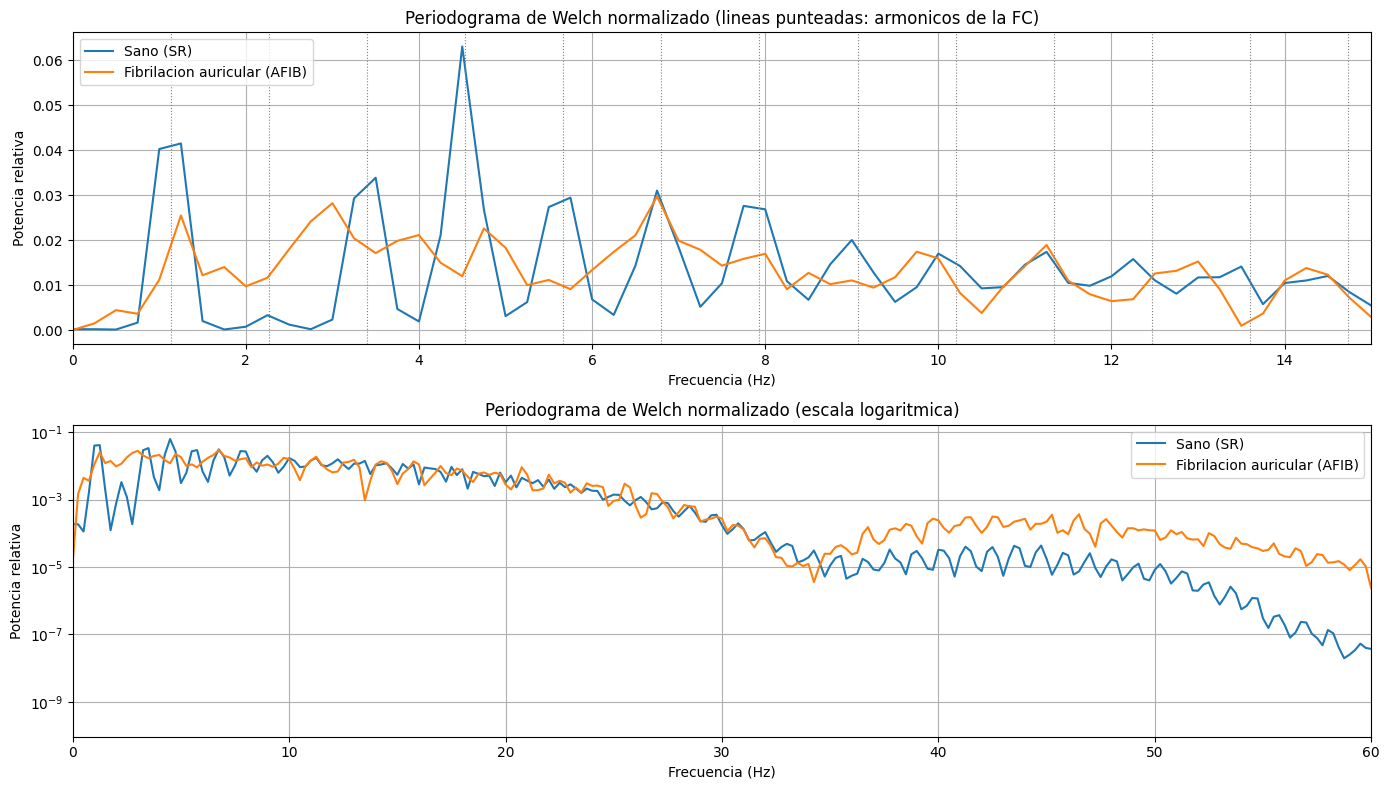

Sano: frecuencia de maxima potencia = 4.5 Hz | 0.5-3 Hz: 9.1 % | 3-10 Hz: 47.4 % | 10-40 Hz: 43.5 %
AFIB: frecuencia de maxima potencia = 6.75 Hz | 0.5-3 Hz: 13.4 % | 3-10 Hz: 45.3 % | 10-40 Hz: 41.3 %


In [22]:
# Parametros escogidos: ventana de 4 s (igual que en el proyecto 1) y 50% de solapamiento
nperseg7 = 2000
noverlap7 = int(nperseg7/2)

f_s, P_s = pwelch(ecg_sano, fs7, 'hann', nperseg7, noverlap7)
f_a, P_a = pwelch(ecg_afib, fs7, 'hann', nperseg7, noverlap7)
print('Resolucion en frecuencia:', fs7/nperseg7, 'Hz')

# Normalizamos por la potencia total entre 0.5 y 40 Hz para comparar la forma
# del espectro sin que influya que una señal tenga mas amplitud que la otra
banda = (f_s >= 0.5) & (f_s <= 40)
P_s_n = P_s / np.sum(P_s[banda])
P_a_n = P_a / np.sum(P_a[banda])

# Armonicos de la frecuencia cardiaca (68 lpm = 1.13 Hz)
fc = 68/60

fig, ax = plt.subplots(2, 1, figsize=(14, 8))
ax[0].plot(f_s, P_s_n, label='Sano (SR)')
ax[0].plot(f_a, P_a_n, label='Fibrilacion auricular (AFIB)')
for k in range(1, 15):
    ax[0].axvline(k*fc, color='gray', ls=':', lw=0.8)
ax[0].set(title='Periodograma de Welch normalizado (lineas punteadas: armonicos de la FC)',
          xlabel='Frecuencia (Hz)', ylabel='Potencia relativa')
ax[0].set_xlim(0, 15)
ax[0].legend(); ax[0].grid()

ax[1].semilogy(f_s, P_s_n, label='Sano (SR)')
ax[1].semilogy(f_a, P_a_n, label='Fibrilacion auricular (AFIB)')
ax[1].set(title='Periodograma de Welch normalizado (escala logaritmica)',
          xlabel='Frecuencia (Hz)', ylabel='Potencia relativa')
ax[1].set_xlim(0, 60)
ax[1].legend(); ax[1].grid()
plt.tight_layout()
plt.show()

# Frecuencia de maxima potencia y reparto de la potencia por bandas
def porcentaje(Pn, a, b):
    return 100*np.sum(Pn[(f_s >= a) & (f_s < b)])

for nombre, Pn in [('Sano', P_s_n), ('AFIB', P_a_n)]:
    print(f'{nombre}: frecuencia de maxima potencia = {f_s[banda][np.argmax(Pn[banda])]} Hz | '
          f'0.5-3 Hz: {porcentaje(Pn, 0.5, 3):.1f} % | '
          f'3-10 Hz: {porcentaje(Pn, 3, 10):.1f} % | '
          f'10-40 Hz: {porcentaje(Pn, 10, 40):.1f} %')

Al comparar los dos periodogramas la diferencia mas clara esta entre 0 y 15 Hz. En el paciente sano la potencia sale en picos bien definidos que caen justo en los multiplos de la frecuencia cardiaca (1.13, 3.4, 4.5, 5.7 Hz...) y entre un pico y otro la potencia baja casi a cero. Esto pasa porque en el ritmo sinusal todos los latidos son casi iguales y llegan siempre al mismo tiempo, entonces la señal se comporta como una señal periodica igual que las de los primeros puntos. La maxima potencia del sano quedo en 4.5 Hz que esta en la zona del QRS, que es la onda con mas energia. En el paciente con fibrilacion no se ven esos picos ordenados sino que la potencia queda mas repartida, porque los latidos llegan a destiempo y la señal deja de repetirse igual. Ademas su maxima potencia quedo en 6.75 Hz, que es casi la misma frecuencia auricular que da el Diagnostics (416 por minuto, como 6.9 Hz), osea que ese pico viene de las ondas f de la fibrilacion.

Tambien el paciente con AFIB tiene mas potencia entre 0.5 y 3 Hz (13.4 % contra 9.1 %) por lo irregular de los latidos, pero en las otras bandas los dos quedaron parecidos. Eso tiene sentido porque en la fibrilacion auricular el problema esta en las auriculas y los ventriculos funcionan normal, entonces el QRS se ve parecido en los dos. Esto concuerda con el proyecto 1, donde tambien se vio que los ritmos regulares y los irregulares se podian diferenciar. Aqui se ve que si el corazon late de forma regular el espectro sale con picos ordenados y si no, sale todo mas regado. Por eso el analisis en frecuencia puede servir para detectar una fibrilacion auricular, por ejemplo en relojes o equipos portatiles que monitorean el corazon todo el tiempo.

Conclusiones

En esta practica se vio que pasar una señal al dominio de la frecuencia permite ver cosas que en el tiempo no se notan, y eso es muy util para las bioseñales. Primero se comprobo que para muestrear bien no basta con el doble de la frecuencia maxima, porque justo en ese limite se puede perder informacion. En un equipo medico esto es importante porque si se muestrea muy bajo se pueden deformar ondas rapidas como el QRS y eso afectaria el diagnostico. Con la fft se pudieron identificar las frecuencias que componian la señal y cuanto aportaba cada una, y con la ifft se recupero la señal sin perder nada. Esto muestra que se puede trabajar en frecuencia para limpiar o analizar una señal y luego volver al tiempo, que es como el medico la necesita ver.

Al poner en cero partes del espectro se puede filtrar una señal y quedarse solo con la informacion que interesa, como se hizo al separar cada componente de la señal compuesta. Con esa misma idea se le quito el ruido de 60 Hz de la red electrica a la señal de ECG y se pudieron ver bien las ondas P y T, que antes estaban tapadas. Como la informacion del corazon esta casi toda entre 0 y 40 Hz y el ruido estaba lejos de esa banda, se pudo eliminar sin dañar la forma del latido, y eso se comprobo con el periodograma de Welch. Esto es clave en bioingenieria porque una señal limpia permite medir bien cosas como el intervalo PR o el segmento ST, que son importantes para detectar problemas cardiacos.

La funcion propia de Welch dio practicamente igual a la de la libreria, lo que ayudo a entender que el metodo parte la señal en pedazos, los promedia y asi da un espectro mas confiable que una sola fft. Tambien se vio que escojer el ancho de la ventana depende de la señal: tiene que ser lo suficientemente larga para que quepan latidos completos, pero sin dejar muy pocos segmentos para promediar. Por ultimo, al comparar un paciente sano con uno con fibrilacion auricular de la misma frecuencia cardiaca, se vio que el ritmo sinusal da picos ordenados en los multiplos de la frecuencia cardiaca porque los latidos son regulares. En la fibrilacion la potencia queda repartida por los latidos irregulares, y aparece un pico cerca de 7 Hz por la actividad desordenada de las auriculas. Esto muestra que el analisis en frecuencia puede servir para diferenciar condiciones cardiacas y apoyar el diagnostico, por ejemplo en equipos que monitorean el corazon de forma continua.

Referencias

S. W. Smith, The Scientist and Engineer’s Guide to Digital Signal Processing, 2nd ed. California Technical Publishing, 1999.
https://www.analog.com/en/resources/technical-books/scientist_engineers_guide.html

SciPy, “scipy.signal.welch — SciPy Manual”.
https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html

J. Zheng, J. Zhang, S. Danioko, H. Yao, H. Guo, C. Rakovski, “A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients,” Scientific Data, vol. 7, no. 1, p. 48, 2020.
https://doi.org/10.1038/s41597-020-0386-x

D. Husser, M. Stridh, L. Sörnmo, S. B. Olsson, A. Bollmann, “Frequency Analysis of Atrial Fibrillation From the Surface Electrocardiogram,” Indian Pacing and Electrophysiology Journal, vol. 4, no. 3, pp. 122–136, 2004.
https://pmc.ncbi.nlm.nih.gov/articles/PMC1501079